# двойной маятник

Два точечных груза $m_1$, $m_2$ на невесомых стержнях длины $l_1$, $l_2$. Трения нет.
Углы $\theta_1$, $\theta_2$ отсчитываются от вертикали вниз; $v_1=\dot\theta_1$, $v_2=\dot\theta_2$, $\delta=\theta_1-\theta_2$.

Уравнения движения:
$$
(m_1+m_2)l_1\ddot\theta_1+m_2l_2\cos\delta\,\ddot\theta_2
=-(m_1+m_2)g\sin\theta_1-m_2l_2v_2^2\sin\delta,
$$
$$
l_2\ddot\theta_2+l_1\cos\delta\,\ddot\theta_1
=l_1v_1^2\sin\delta-g\sin\theta_2.
$$

Решаем систему для $y=(\theta_1,\theta_2,v_1,v_2)$ без линеаризации.
Начальные углы — 0.1 и 0.05 рад, скорости нулевые. Массы — по 1 кг, длины — по 1 м.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

g = 9.81
m_1 = m_2 = 1.0
l_1 = l_2 = 1.0
y_0 = np.array([0.1, 0.05, 0.0, 0.0])
t_end = 12.0
steps = [0.04, 0.02, 0.01]


Для $\dot y=f(y)$ шаг rk4 имеет вид
$$
k_1=f(y_n),\quad k_2=f(y_n+hk_1/2),\quad
k_3=f(y_n+hk_2/2),\quad k_4=f(y_n+hk_3),
$$
$$y_{n+1}=y_n+\frac{h}{6}(k_1+2k_2+2k_3+k_4).$$

Метод Адамса–Бэшфорта второго порядка:
$$y_{n+1}=y_n+\frac{h}{2}\bigl(3f(y_n)-f(y_{n-1})\bigr).$$
Первое значение $y_1$ для него получаем одним шагом rk4.


In [2]:
def rhs(y):  # угловые скорости и ускорения одного маятника или ансамбля
    theta_1, theta_2, v_1, v_2 = np.moveaxis(y, -1, 0)
    delta = theta_1 - theta_2
    c = np.cos(delta)
    s = np.sin(delta)
    b_1 = -(m_1 + m_2) * g * np.sin(theta_1) - m_2 * l_2 * v_2**2 * s
    b_2 = l_1 * v_1**2 * s - g * np.sin(theta_2)
    a_1 = (b_1 - m_2 * c * b_2) / (l_1 * (m_1 + m_2 * s**2))
    a_2 = (b_2 - l_1 * c * a_1) / l_2
    return np.stack((v_1, v_2, a_1, a_2), axis=-1)


def rk4_step(y, h):  # шаг rk4
    k_1 = rhs(y)
    k_2 = rhs(y + h * k_1 / 2)
    k_3 = rhs(y + h * k_2 / 2)
    k_4 = rhs(y + h * k_3)
    return y + h * (k_1 + 2 * k_2 + 2 * k_3 + k_4) / 6


def solve(method, h, y_start=None, t_stop=None):  # интегрирование заданных состояний на общей сетке
    y_start = y_0 if y_start is None else np.asarray(y_start)
    t_stop = t_end if t_stop is None else t_stop
    n = round(t_stop / h)
    if n < 1 or not np.isclose(n * h, t_stop, rtol=1e-12, atol=1e-12):
        raise ValueError('время расчёта должно быть кратно положительному шагу')
    t = np.linspace(0, t_stop, n + 1)
    dt = t[1] - t[0]
    y = np.empty((n + 1,) + y_start.shape)
    y[0] = y_start
    if method == 'rk4':
        for i in range(n):
            y[i + 1] = rk4_step(y[i], dt)
    elif method == 'ab2':
        # Первый шаг многошагового метода делаем через rk4.
        y[1] = rk4_step(y[0], dt)
        f_prev = rhs(y[0])
        for i in range(1, n):
            f = rhs(y[i])
            y[i + 1] = y[i] + dt * (3 * f - f_prev) / 2
            f_prev = f
    else:
        raise ValueError('неизвестный метод')
    return t, y


Координаты нижнего груза относительно точки подвеса:
$$x_2=l_1\sin\theta_1+l_2\sin\theta_2,\qquad
z_2=-l_1\cos\theta_1-l_2\cos\theta_2.$$

Полная энергия $E=T+U$, где
$$
T=\frac{(m_1+m_2)l_1^2v_1^2}{2}+\frac{m_2l_2^2v_2^2}{2}
+m_2l_1l_2v_1v_2\cos\delta,
$$
$$U=(m_1+m_2)gl_1(1-\cos\theta_1)+m_2gl_2(1-\cos\theta_2).$$
Нуль потенциальной энергии выбран в нижнем положении равновесия. Без трения $E(t)=E(0)$.


In [3]:
def lower_position(y):  # координаты нижнего груза
    theta_1, theta_2 = y[..., 0], y[..., 1]
    x = l_1 * np.sin(theta_1) + l_2 * np.sin(theta_2)
    z = -l_1 * np.cos(theta_1) - l_2 * np.cos(theta_2)
    return x, z


def energy(y):  # полная механическая энергия
    theta_1, theta_2, v_1, v_2 = np.moveaxis(y, -1, 0)
    e_k = ((m_1 + m_2) * l_1**2 * v_1**2 / 2
           + m_2 * l_2**2 * v_2**2 / 2
           + m_2 * l_1 * l_2 * v_1 * v_2 * np.cos(theta_1 - theta_2))
    e_p = (2 * (m_1 + m_2) * g * l_1 * np.sin(theta_1 / 2)**2
           + 2 * m_2 * g * l_2 * np.sin(theta_2 / 2)**2)
    return e_k + e_p


results = []
for h in steps:
    t, y_rk4 = solve('rk4', h)
    _, y_ab2 = solve('ab2', h)
    results.append((t, y_rk4, y_ab2))

names = ['rk4', 'Адамс–Бэшфорт']
colors = ['tab:blue', 'tab:orange']
styles = ['-', '--']
e_0 = energy(y_0)


## углы и траектория


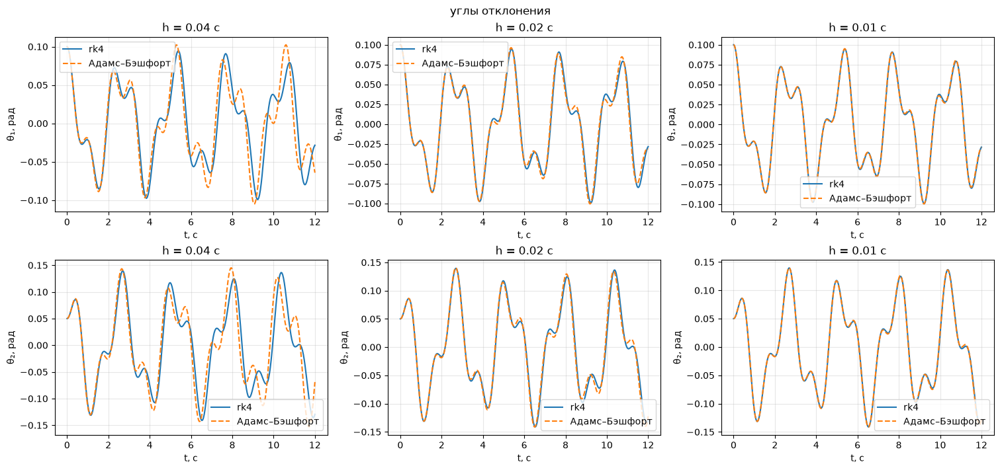

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), constrained_layout=True)
for j, (h, (t, *solutions)) in enumerate(zip(steps, results)):
    for y, name, color, style in zip(solutions, names, colors, styles):
        axes[0, j].plot(t, y[:, 0], label=name, color=color, linestyle=style)
        axes[1, j].plot(t, y[:, 1], label=name, color=color, linestyle=style)
    for i, label in enumerate(['θ₁, рад', 'θ₂, рад']):
        axes[i, j].set(title=f'h = {h} с', xlabel='t, с', ylabel=label)
        axes[i, j].grid(alpha=0.3)
        axes[i, j].legend()
fig.suptitle('углы отклонения')
plt.show()


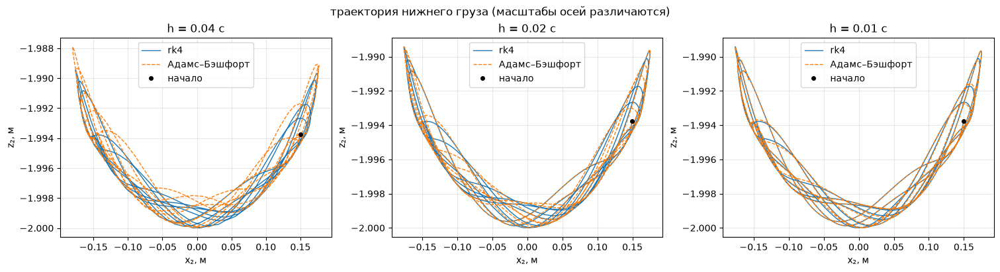

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, h, (t, *solutions) in zip(axes, steps, results):
    for y, name, color, style in zip(solutions, names, colors, styles):
        x, z = lower_position(y)
        ax.plot(x, z, label=name, color=color, linestyle=style, linewidth=1)
    x_0, z_0 = lower_position(y_0[None, :])
    ax.plot(x_0, z_0, 'ko', markersize=4, label='начало', zorder=5)
    ax.set(title=f'h = {h} с', xlabel='x₂, м', ylabel='z₂, м')
    ax.ticklabel_format(axis='y', style='plain', useOffset=False)
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle('траектория нижнего груза (масштабы осей различаются)')
plt.show()


## полная энергия

Для каждого метода показаны все три шага. Масштабы оси энергии на двух графиках различаются.


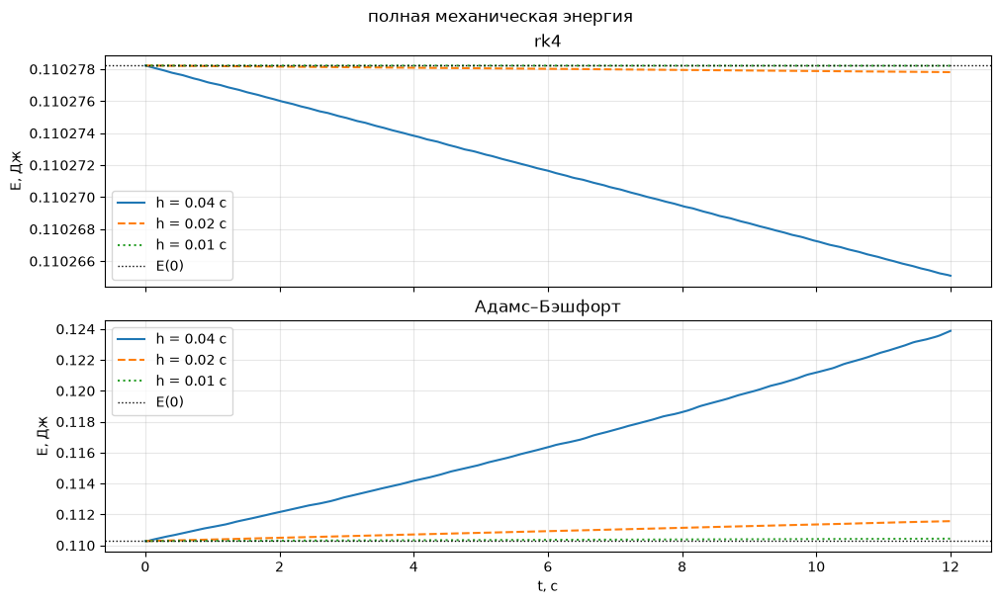

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, constrained_layout=True)
step_colors = ['tab:blue', 'tab:orange', 'tab:green']
step_styles = ['-', '--', ':']
for i, (ax, name) in enumerate(zip(axes, names)):
    for h, (t, *solutions), color, style in zip(steps, results, step_colors, step_styles):
        ax.plot(t, energy(solutions[i]), label=f'h = {h} с', color=color, linestyle=style)
    ax.axhline(e_0, color='black', linestyle=':', linewidth=1, label='E(0)')
    ax.set(title=name, ylabel='E, Дж')
    ax.ticklabel_format(axis='y', style='plain', useOffset=False)
    ax.grid(alpha=0.3)
    ax.legend()
axes[1].set_xlabel('t, с')
fig.suptitle('полная механическая энергия')
plt.show()


## сравнение шагов

Численный эталон — расчёт rk4 с шагом 0.0005 с. Ошибки углов измеряем в общих узлах сеток на интервале 0–12 с:
$$\varepsilon_j=\max_n|\theta_{j,n}-\theta_{j,\mathrm{эт}}(t_n)|,\qquad
\varepsilon_E=\max_n\frac{|E_n-E_0|}{E_0}\cdot100\%.$$


In [7]:
h_ref = 0.0005
t_ref, y_ref = solve('rk4', h_ref)

print(f"{'шаг, с':>8} {'метод':>15} {'ошибка θ₁, рад':>18} {'ошибка θ₂, рад':>18} {'ошибка E, %':>16}")
for h, (t, *solutions) in zip(steps, results):
    indices = np.rint(t / (t_ref[1] - t_ref[0])).astype(int)
    for name, y in zip(names, solutions):
        errors = np.max(np.abs(y[:, :2] - y_ref[indices, :2]), axis=0)
        energy_error = 100 * np.max(np.abs(energy(y) - e_0)) / e_0
        print(f'{h:8.2f} {name:>15} {errors[0]:18.6e} {errors[1]:18.6e} {energy_error:16.6e}')


  шаг, с           метод     ошибка θ₁, рад     ошибка θ₂, рад      ошибка E, %
    0.04             rk4       5.017207e-05       7.207037e-05     1.191192e-02
    0.04   Адамс–Бэшфорт       5.456666e-02       7.571661e-02     1.233278e+01
    0.02             rk4       3.168413e-06       4.551269e-06     3.739574e-04
    0.02   Адамс–Бэшфорт       1.336567e-02       1.812364e-02     1.167608e+00
    0.01             rk4       1.994468e-07       2.861833e-07     1.168445e-05
    0.01   Адамс–Бэшфорт       3.324345e-03       4.471413e-03     1.397813e-01


При уменьшении шага решения обоих методов сближаются. Ошибка углов у rk4 уменьшается примерно в 16 раз при делении шага пополам, у метода Адамса–Бэшфорта — примерно в 4 раза.
У метода Адамса–Бэшфорта заметны накопление фазовой ошибки и рост энергии. У rk4 отклонение энергии существенно меньше. Изменение энергии здесь связано с численным методом: в исходной системе трения нет.


## большие отклонения

Берём $\theta_1(0)=120^\circ$, $\theta_2(0)=-10^\circ$, начальные скорости нулевые.
Параметры маятника прежние, время расчёта — 25 с. Меняем только первый начальный угол:
$$\theta_1^{(\varepsilon)}(0)=\theta_1(0)+\varepsilon,\qquad
\varepsilon=10^{-3},\ 10^{-4},\ 10^{-5}\ \text{рад}.$$

Отдельно сравниваем разные начальные условия при одном шаге и одинаковые начальные условия при уменьшении шага.
Для rk4 и метода Адамса–Бэшфорта используем шаги 0.01, 0.005 и 0.0025 с.
Численный эталон — rk4 с шагом 0.000625 с; дополнительно проверяем его шагом 0.0003125 с.


In [8]:
large_start = np.array([np.deg2rad(120), np.deg2rad(-10), 0.0, 0.0])
t_large = 25.0
large_steps = [0.01, 0.005, 0.0025]
perturbations = np.array([1e-3, 1e-4, 1e-5])
ensemble_offsets = np.arange(-4, 6) * 1e-4
h_large_ref = 0.000625
h_check = h_large_ref / 2

# Все начальные условия считаем вместе, включая десять маятников для анимации.
offsets = np.unique(np.round(np.r_[0.0, perturbations, ensemble_offsets], 12))
large_states = np.tile(large_start, (len(offsets), 1))
large_states[:, 0] += offsets
base_index = np.argmin(np.abs(offsets))
perturbed_indices = [np.argmin(np.abs(offsets - eps)) for eps in perturbations]
ensemble_indices = [np.argmin(np.abs(offsets - eps)) for eps in ensemble_offsets]
main_indices = [base_index] + perturbed_indices

large_results = {}
for method in ['rk4', 'ab2']:
    for h in large_steps:
        large_results[method, h] = solve(method, h, large_states, t_large)

t_large_ref, y_large_ref = solve('rk4', h_large_ref, large_states, t_large)
t_check, y_check = solve('rk4', h_check, large_states, t_large)


Расхождение измеряем по обоим углам с учётом их периодичности:
$$d(a,b)=\sqrt{\sum_{j=1}^2
\operatorname{atan2}^2\!\left(\sin(\theta_j^a-\theta_j^b),\cos(\theta_j^a-\theta_j^b)\right)}.$$
Так поворот на $2\pi$ не считается различием положений.
Расхождение от начального возмущения — $D_\varepsilon(t)=d(y^{(\varepsilon)}(t),y^{(0)}(t))$.
Сравнение сеток делаем только в общих узлах, без интерполяции.


In [9]:
def angle_distance(a, b):  # расстояние по двум углам с разностями в пределах от −π до π
    delta = a[..., :2] - b[..., :2]
    delta = np.arctan2(np.sin(delta), np.cos(delta))
    return np.linalg.norm(delta, axis=-1)


def first_interval(t, condition):  # конец непрерывного интервала от нуля до первого нарушения
    failed = np.flatnonzero(~condition)
    return t[max(0, failed[0] - 1)] if len(failed) else t[-1]


ref_difference = angle_distance(y_large_ref, y_check[::2])
ref_separation = angle_distance(y_large_ref, y_large_ref[:, base_index, None, :])

step_errors = {}
separations = {}
for (method, h), (t, y) in large_results.items():
    stride = round(h / h_large_ref)
    reference = y_large_ref[::stride]
    step_errors[method, h] = angle_distance(y, reference)
    separations[method, h] = angle_distance(y, y[:, base_index, None, :])


## интервал доверия

Вклад шага для каждого решения оцениваем как
$$e_h^{(j)}(t)=d(y_h^{(j)},y_{\rm ref}^{(j)})+
 d(y_{\rm ref}^{(j)},y_{\rm check}^{(j)}).$$
Второе слагаемое учитывает расхождение двух самых мелких сеток.
Для каждой пары принимаем результат до первого нарушения хотя бы одного условия:
$$\max(e_h^{(0)},e_h^{(\varepsilon)})\leq 0.01\ \text{рад},\qquad
 e_h^{(0)}+e_h^{(\varepsilon)}\leq 0.1D_{\varepsilon,\rm ref}(t).$$

То есть изменение каждого решения при уточнении должно быть небольшим, а суммарный вклад шага — не больше 10% исследуемого расхождения.
Это практическая проверка при выбранных допусках, а не строгая оценка ошибки.
Для самого эталона используем те же условия с $e^{(j)}=d(y_{\rm ref}^{(j)},y_{\rm check}^{(j)})$.


In [10]:
angle_tolerance = 0.01
relative_tolerance = 0.1


def reliable_pair(error, separation, index):  # сравнение ошибки двух решений с их расхождением
    pair_error = error[:, base_index] + error[:, index]
    absolute_error = np.maximum(error[:, base_index], error[:, index])
    return ((absolute_error <= angle_tolerance)
            & (pair_error <= relative_tolerance * separation[:, index]))


ref_limits = {}
for index in range(len(offsets)):
    if index != base_index:
        valid = reliable_pair(ref_difference, ref_separation, index)
        ref_limits[index] = first_interval(t_large_ref, valid)

trust_limits = {}
print(f"{'метод':>15} {'h, с':>9} {'ε, рад':>10} {'доверяем до, с':>16}")
for method, name in zip(['rk4', 'ab2'], names):
    for h in large_steps:
        t, _ = large_results[method, h]
        stride = round(h / h_large_ref)
        error = step_errors[method, h] + ref_difference[::stride]
        for eps, index in zip(perturbations, perturbed_indices):
            valid = reliable_pair(error, ref_separation[::stride], index)
            limit = first_interval(t, valid)
            trust_limits[method, h, index] = limit
            print(f'{name:>15} {h:9.4f} {eps:10.0e} {limit:16.3f}')
print('\nПроверка численного эталона:')
for eps, index in zip(perturbations, perturbed_indices):
    print(f'ε = {eps:.0e} рад: до {ref_limits[index]:.3f} с')


          метод      h, с     ε, рад   доверяем до, с
            rk4    0.0100      1e-03            7.800
            rk4    0.0100      1e-04            2.240
            rk4    0.0100      1e-05            0.580
            rk4    0.0050      1e-03           10.130
            rk4    0.0050      1e-04           14.845
            rk4    0.0050      1e-05           15.415
            rk4    0.0025      1e-03           15.190
            rk4    0.0025      1e-04           15.030
            rk4    0.0025      1e-05           15.950
  Адамс–Бэшфорт    0.0100      1e-03            0.070
  Адамс–Бэшфорт    0.0100      1e-04            0.030
  Адамс–Бэшфорт    0.0100      1e-05            0.010
  Адамс–Бэшфорт    0.0050      1e-03            0.135
  Адамс–Бэшфорт    0.0050      1e-04            0.045
  Адамс–Бэшфорт    0.0050      1e-05            0.015
  Адамс–Бэшфорт    0.0025      1e-03            0.278
  Адамс–Бэшфорт    0.0025      1e-04            0.088
  Адамс–Бэшфорт    0.0025   

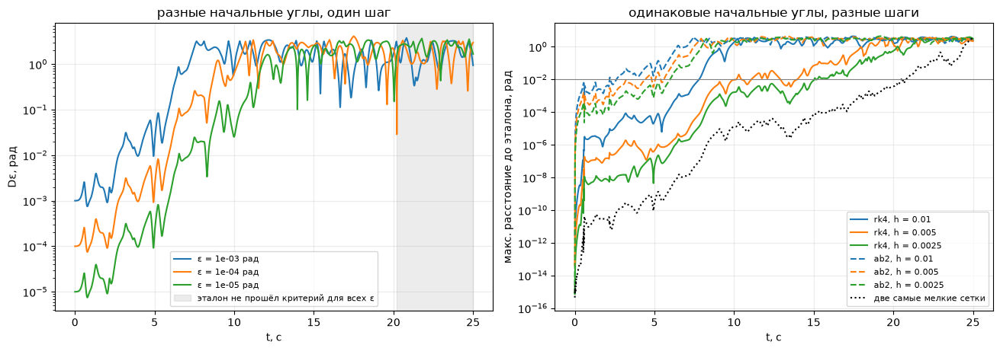

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for eps, index, color in zip(perturbations, perturbed_indices, step_colors):
    axes[0].semilogy(t_large_ref, ref_separation[:, index], color=color,
                     label=f'ε = {eps:.0e} рад')
ref_common_limit = min(ref_limits[index] for index in perturbed_indices)
axes[0].axvspan(ref_common_limit, t_large, color='gray', alpha=0.15,
               label='эталон не прошёл критерий для всех ε')
axes[0].set(title='разные начальные углы, один шаг', xlabel='t, с', ylabel='Dε, рад')

for method, style in [('rk4', '-'), ('ab2', '--')]:
    for h, color in zip(large_steps, step_colors):
        t, _ = large_results[method, h]
        error = np.max(step_errors[method, h][:, main_indices], axis=1)
        axes[1].semilogy(t[1:], error[1:], color=color, linestyle=style,
                         label=f'{method}, h = {h}')
ref_error_max = np.max(ref_difference[:, main_indices], axis=1)
axes[1].semilogy(t_large_ref[1:], ref_error_max[1:], ':', color='black',
                 label='две самые мелкие сетки')
axes[1].axhline(angle_tolerance, color='gray', linewidth=0.8)
axes[1].set(title='одинаковые начальные углы, разные шаги', xlabel='t, с',
            ylabel='макс. расстояние до эталона, рад')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
plt.show()


Ниже одно и то же начальное возмущение рассчитано с разными шагами rk4.
Вертикальная линия отмечает конец интервала доверия для шага 0.0025 с.
Справа от неё график показывает результат расчёта, но выбранный критерий точности уже не выполнен.


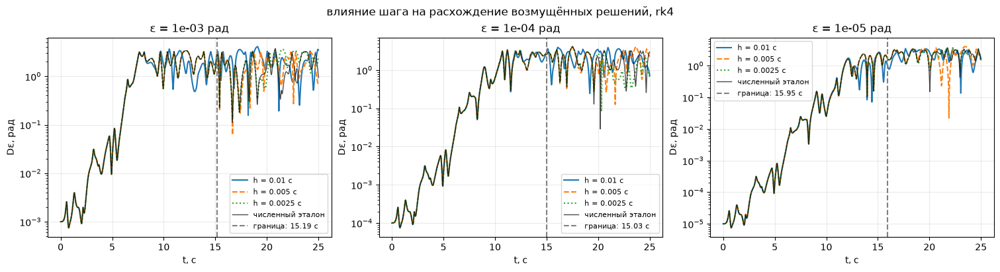

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, eps, index in zip(axes, perturbations, perturbed_indices):
    for h, color, style in zip(large_steps, step_colors, step_styles):
        t, _ = large_results['rk4', h]
        ax.semilogy(t, separations['rk4', h][:, index], color=color,
                    linestyle=style, label=f'h = {h} с')
    ax.semilogy(t_large_ref, ref_separation[:, index], color='black',
                linewidth=1, alpha=0.7, label='численный эталон')
    limit = trust_limits['rk4', large_steps[-1], index]
    ax.axvline(limit, color='gray', linestyle='--', label=f'граница: {limit:.2f} с')
    ax.set(title=f'ε = {eps:.0e} рад', xlabel='t, с', ylabel='Dε, рад')
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.suptitle('влияние шага на расхождение возмущённых решений, rk4')
plt.show()


Порядок сходимости проверяем отдельно на первых 2 с, пока ошибка шага ещё мала.
В таблице берём максимальную ошибку обоих углов для исходного состояния и трёх возмущений.


In [13]:
print(f"{'метод':>15} {'h, с':>9} {'ошибка до 2 с, рад':>21} {'порядок':>10}")
for method, name in zip(['rk4', 'ab2'], names):
    previous_error = None
    for h in large_steps:
        t, _ = large_results[method, h]
        error = np.max(step_errors[method, h][t <= 2.0][:, main_indices])
        order = '—' if previous_error is None else f'{np.log2(previous_error / error):.2f}'
        print(f'{name:>15} {h:9.4f} {error:21.6e} {order:>10}')
        previous_error = error


          метод      h, с    ошибка до 2 с, рад    порядок
            rk4    0.0100          3.515864e-06          —
            rk4    0.0050          1.853383e-07       4.25
            rk4    0.0025          1.243441e-08       3.90
  Адамс–Бэшфорт    0.0100          6.582844e-03          —
  Адамс–Бэшфорт    0.0050          1.545130e-03       2.09
  Адамс–Бэшфорт    0.0025          3.847484e-04       2.01


## движение маятника

Анимации показывают первые 15 с решения rk4 с шагом 0.000625 с.
Проверяем этот участок по расчёту с вдвое меньшим шагом, включая все состояния ансамбля.
След нижнего груза сохраняется за последние 3 с. На графике углов движутся отметка времени и точки обоих углов.
Углы здесь непрерывные, без приведения к интервалу от −π до π.


In [14]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

t_animation = 15.0
fps = 25
frame_stride = round(1 / (fps * h_large_ref))
frame_indices = np.arange(0, round(t_animation / h_large_ref) + 1, frame_stride)
frame_t = t_large_ref[frame_indices]
frame_y = y_large_ref[frame_indices]

animation_mask = t_large_ref <= t_animation
animation_error = np.max(ref_difference[animation_mask][:, ensemble_indices])
ensemble_limit = min(ref_limits[index] for index in ensemble_indices if index != base_index)
assert t_animation <= ensemble_limit
print(f'Расхождение сеток на участке анимации: не более {animation_error:.3e} рад')
print(f'Общий интервал доверия для ансамбля: 0–{ensemble_limit:.3f} с')
e_animation = energy(y_large_ref[animation_mask][:, ensemble_indices])
e_initial = energy(large_states[ensemble_indices])
energy_drift = np.max(np.abs(e_animation - e_initial) / e_initial)
print(f'Максимальное относительное изменение энергии: {energy_drift:.3e}')
plt.rcParams['animation.embed_limit'] = 80


Расхождение сеток на участке анимации: не более 4.933e-03 рад
Общий интервал доверия для ансамбля: 0–16.109 с
Максимальное относительное изменение энергии: 2.629e-10


In [15]:
def animate_pendulum(t, y, trail_seconds=3):  # маятник, след груза и синхронный график углов
    fig, axes = plt.subplots(1, 2, figsize=(9, 4), dpi=75, constrained_layout=True)
    reach = 1.1 * (l_1 + l_2)
    axes[0].set(xlim=(-reach, reach), ylim=(-reach, reach), xlabel='x, м', ylabel='z, м')
    axes[0].set_aspect('equal')
    axes[0].plot(0, 0, 'ko', markersize=4)
    rod, = axes[0].plot([], [], '-', color='0.3', linewidth=1.5)
    mass_1, = axes[0].plot([], [], 'o', color='tab:blue', markersize=6)
    mass_2, = axes[0].plot([], [], 'o', color='tab:orange', markersize=6)
    trail, = axes[0].plot([], [], color='tab:orange', linewidth=0.8, alpha=0.6)
    x_1, z_1 = l_1 * np.sin(y[:, 0]), -l_1 * np.cos(y[:, 0])
    x_2, z_2 = lower_position(y)
    trail_length = round(trail_seconds / (t[1] - t[0]))

    low, high = y[:, :2].min(), y[:, :2].max()
    margin = 0.08 * (high - low)
    axes[1].set(xlim=(0, t[-1]), ylim=(low - margin, high + margin),
                xlabel='t, с', ylabel='θ, рад')
    lines, dots = [], []
    for j, color in enumerate(['tab:blue', 'tab:orange']):
        line, = axes[1].plot([], [], color=color, label=f'θ{j + 1}')
        dot, = axes[1].plot([], [], 'o', color=color, markersize=4)
        lines.append(line)
        dots.append(dot)
    cursor = axes[1].axvline(0, color='gray', linestyle='--', linewidth=0.8)
    axes[1].legend()
    for ax in axes:
        ax.grid(alpha=0.25)
    title = fig.suptitle('t = 0.00 с')

    def update(i):  # одно и то же время для положения, следа и графика углов
        rod.set_data([0, x_1[i], x_2[i]], [0, z_1[i], z_2[i]])
        mass_1.set_data([x_1[i]], [z_1[i]])
        mass_2.set_data([x_2[i]], [z_2[i]])
        begin = max(0, i - trail_length)
        trail.set_data(x_2[begin:i + 1], z_2[begin:i + 1])
        for j, (line, dot) in enumerate(zip(lines, dots)):
            line.set_data(t[:i + 1], y[:i + 1, j])
            dot.set_data([t[i]], [y[i, j]])
        cursor.set_xdata([t[i], t[i]])
        title.set_text(f't = {t[i]:.2f} с')
        return [rod, mass_1, mass_2, trail, cursor, title] + lines + dots

    animation = FuncAnimation(fig, update, frames=len(t),
                              interval=1000 * (t[1] - t[0]), blit=False)
    plt.close(fig)
    return animation


pendulum_animation = animate_pendulum(frame_t, frame_y[:, base_index])
display(HTML(pendulum_animation.to_jshtml(default_mode='once')))


## ансамбль

Десять маятников с общим подвесом и одинаковыми параметрами.
Первый начальный угол меняется на $\varepsilon_j=(-4,-3,\ldots,5)\cdot10^{-4}$ рад;
второй угол и начальные скорости одинаковые. Каждый цвет соответствует одному начальному условию.


In [16]:
def animate_ensemble(t, y, angle_offsets):  # десять двойных маятников в одной системе координат
    fig, ax = plt.subplots(figsize=(6.5, 4.8), dpi=75)
    fig.subplots_adjust(right=0.72)
    reach = 1.1 * (l_1 + l_2)
    ax.set(xlim=(-reach, reach), ylim=(-reach, reach), xlabel='x, м', ylabel='z, м')
    ax.set_aspect('equal')
    ax.grid(alpha=0.25)
    ax.plot(0, 0, 'ko', markersize=4, zorder=5)
    colors = plt.cm.tab10(np.arange(len(angle_offsets)))
    x_1, z_1 = l_1 * np.sin(y[..., 0]), -l_1 * np.cos(y[..., 0])
    x_2, z_2 = lower_position(y)
    rods = []
    for eps, color in zip(angle_offsets, colors):
        rod, = ax.plot([], [], '-o', color=color, linewidth=1.2, markersize=4,
                       markevery=[1, 2], alpha=0.8, label=f'{eps:+.0e} рад')
        rods.append(rod)
    ax.legend(title='Δθ₁(0)', loc='center left', bbox_to_anchor=(1.02, 0.5),
              frameon=False, fontsize=8)
    title = ax.set_title('t = 0.00 с')

    def update(i):  # положения всех маятников в один момент времени
        for j, rod in enumerate(rods):
            rod.set_data([0, x_1[i, j], x_2[i, j]], [0, z_1[i, j], z_2[i, j]])
        title.set_text(f't = {t[i]:.2f} с')
        return rods + [title]

    animation = FuncAnimation(fig, update, frames=len(t),
                              interval=1000 * (t[1] - t[0]), blit=False)
    plt.close(fig)
    return animation


ensemble_animation = animate_ensemble(frame_t, frame_y[:, ensemble_indices], ensemble_offsets)
display(HTML(ensemble_animation.to_jshtml(default_mode='once')))


## вывод

Малые изменения начального угла приводят к заметно разным движениям. На первых секундах этот результат сохраняется при уменьшении шага. Позже начинают расходиться и расчёты с одинаковыми начальными условиями, поэтому одно расхождение траекторий ещё не доказывает точность результата.

При rk4 с шагом 0.0025 с выбранный критерий выполняется до 15.19, 15.03 и 15.95 с для возмущений $10^{-3}$, $10^{-4}$ и $10^{-5}$ рад соответственно. Общий интервал — **0–15.03 с**. Сравнение шагов 0.000625 и 0.0003125 с даёт общий интервал **0–20.20 с**. После него точность траекторий этим расчётом не подтверждена; граница зависит от допусков и начальных условий.

Для метода Адамса–Бэшфорта выбранные шаги слишком велики, чтобы точность самих траекторий удовлетворяла этому критерию при столь малых возмущениях. На коротком участке наблюдаемые порядки сходимости близки к 4 у rk4 и к 2 у метода Адамса–Бэшфорта.

Анимации ограничены первыми 15 с: для всех десяти маятников проверка выполняется до 16.11 с. Относительное изменение энергии на участке анимаций не превышает $2.7\cdot10^{-10}$, но само по себе сохранение энергии не задаёт интервал точности траектории.
